# Analysis tests: validation of the method and of the lab-axis approximation

This notebook shows graphically every test run on the analysis code in `src/step_analysis/`. It answers two questions:

1. **Does the new code reproduce the previous analysis?** The code was ported from `DeCIMo-analysis` and made faster.
   - §1: unit tests on synthetic data with known answers.
   - §2: the new functions compared with the previous functions (reference copies in `src/step_analysis/validation/previous_code.py`) on every real step trial.
   - §3: the new pipeline compared with the saved previous results (`AllQtyDF.csv`, `StepDataframe.csv`), first on the exact files used before, then on the open data.
   - §4: a visual check of real trials.
2. **Are the lab x / y axes an acceptable approximation of the participant's ML / AP axes at perturbation initiation?** (§5)

§6 runs the automated test suite (`pytest`).

The previous pseudonyms are only used in memory, to locate the previous files. All outputs use the open-data codes (S0–S20).

## 0. Setup

In [1]:
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.path import Path as MplPath
from shapely.geometry import LineString

from step_analysis import config, data_io, pipeline
from step_analysis.methods import classification, geometry, kinematics
from step_analysis.plotting import figures, style
from step_analysis.validation import previous_code as ref
from step_analysis.validation import previous_results, synthetic

%matplotlib inline
style.apply_style()
pd.set_option("display.precision", 3)
RNG = np.random.default_rng(0)
HAS_PREVIOUS = previous_results.previous_raw_available()
print("Previous analysis files available:", HAS_PREVIOUS)

Previous analysis files available: True


## 1. Unit tests on synthetic data

### 1.1 Time derivative

`kinematics.temporal_deriv` uses `np.gradient(edge_order=2)`, which is the same finite-difference scheme as the previous `TemporalDeriv` loop: central differences inside, second-order one-sided differences at the ends. Test signal: $x(t) = \sin(4\pi t)$ sampled at 200 Hz.

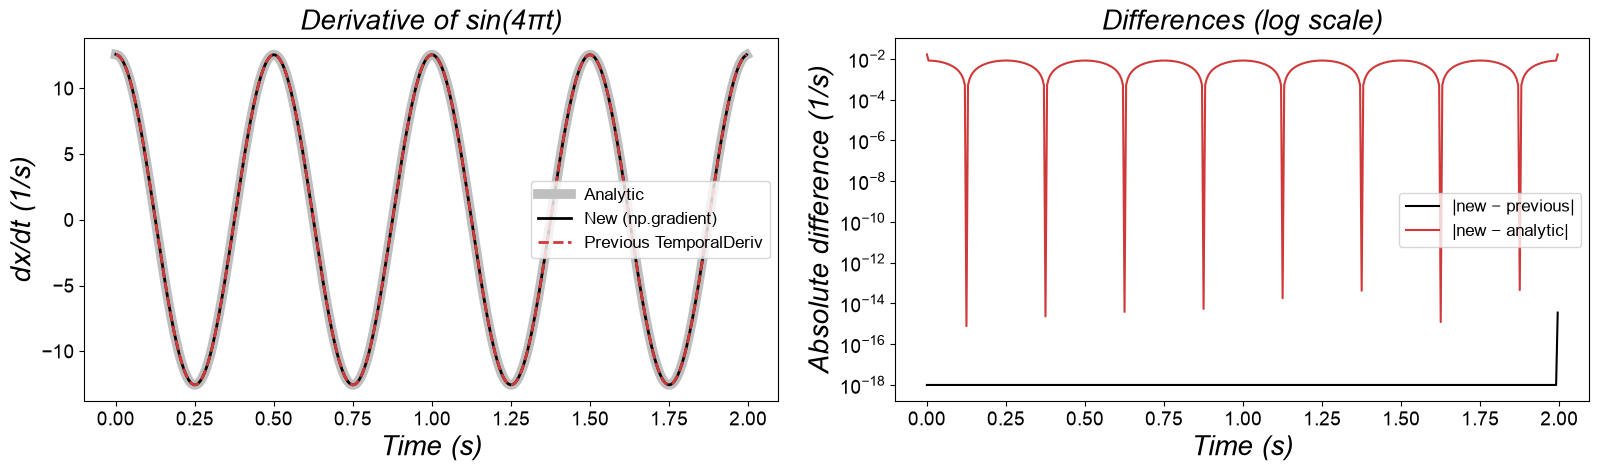

max |new - previous| = 3.6e-15  (floating point rounding)
max |new - analytic| = 1.7e-02  (discretisation error, O(dt^2))


In [2]:
t = np.arange(400) * config.DT
x = np.sin(4 * np.pi * t)
exact = 4 * np.pi * np.cos(4 * np.pi * t)
new, old = kinematics.temporal_deriv(x), ref.TemporalDeriv(x, config.DT)

fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, 0.8 * style.FIG_HEIGHT))
axes[0].plot(t, exact, color="0.75", lw=7, label="Analytic")
axes[0].plot(t, new, color="k", lw=2, label="New (np.gradient)")
axes[0].plot(t, old, color="#D03939", lw=2, ls="--", label="Previous TemporalDeriv")
axes[0].legend(fontsize=style.FONT_SIZE - 8)
style.set_labels(axes[0], "Time (s)", "dx/dt (1/s)", "Derivative of sin(4πt)")
axes[1].semilogy(t, np.abs(new - old) + 1e-18, color="k", lw=1.5, label="|new − previous|")
axes[1].semilogy(t, np.abs(new - exact), color="#D03939", lw=1.5, label="|new − analytic|")
axes[1].legend(fontsize=style.FONT_SIZE - 8)
style.set_labels(axes[1], "Time (s)", "Absolute difference (1/s)", "Differences (log scale)")
for ax in axes:
    ax.tick_params(labelsize=style.FONT_SIZE - 6)
fig.tight_layout(); plt.show()
print(f"max |new - previous| = {np.max(np.abs(new - old)):.1e}  (floating point rounding)")
print(f"max |new - analytic| = {np.max(np.abs(new - exact)):.1e}  (discretisation error, O(dt^2))")

### 1.2 Step detection on a synthetic step

The right toe moves 30 cm forward with a minimum-jerk profile between frames 300 and 360 (grey band). The detector's t_begin must lie between the true motion onset and the frame where the speed exceeds 10 % of its peak (dotted lines). t_end must lie between the falling 10 % crossing and the true motion end.

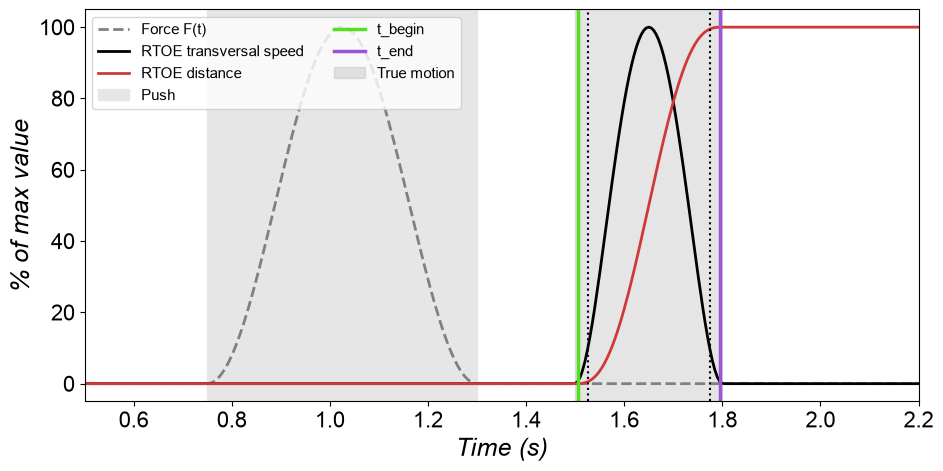

Detected: foot ['R'], [t_begin, t_end] = [[301, 359]] frames
Bounds:   t_begin in [300, 305.2],  t_end in [354.8, 360]
Previous StepDetector: ['R'], [[np.int64(301), np.int64(359)]]  -> identical: True


In [3]:
begin, end = 300, 360
trial = synthetic.synthetic_trial("R", (0.0, 0.3), step_frames=(begin, end), push_frames=(150, 260))
feet, steps, diag = kinematics.step_detector(trial["RTOE"], trial["LTOE"], return_diagnostics=True)
up, down = synthetic.threshold_crossing(begin, end)

fig, ax = plt.subplots(figsize=(style.FIG_WIDTH * 1.2, 0.8 * style.FIG_HEIGHT))
figures.plot_step_detection(ax, trial, diag, steps, feet, perturbation=(150, 260))
ax.axvspan(begin * config.DT, end * config.DT, color="0.6", alpha=0.25, zorder=0, label="True motion")
for f in (up, down):
    ax.axvline(f * config.DT, color="k", ls=":", lw=1.5)
ax.set_xlim(0.5, 2.2)
ax.legend(fontsize=style.FONT_SIZE - 9, loc="upper left", ncol=2)
fig.tight_layout(); plt.show()

old_feet, old_steps = ref.StepDetector(trial["RTOE"], trial["LTOE"], config.DT)
print(f"Detected: foot {feet}, [t_begin, t_end] = {steps} frames")
print(f"Bounds:   t_begin in [{begin}, {up:.1f}],  t_end in [{down:.1f}, {end}]")
print(f"Previous StepDetector: {old_feet}, {old_steps}  -> identical: {feet == old_feet and steps == old_steps}")

### 1.3 Equivalence of the low-level functions on random inputs

Each new function is compared with its previous counterpart, or with the library the previous code used, on many random inputs:
- **`find_speed_peaks` vs `FindPeaks`**: 300 random multi-bump speed curves.
- **`step_detector` vs `StepDetector`**: 7 synthetic trials (5 strategies, no step, leg abduction), each in default and exception mode.
- **`segments_intersect` vs `shapely.LineString.intersects`**: 6000 random segment pairs, plus 6000 pairs on a 4 × 4 integer grid. The grid creates many touching and collinear cases.
- **`first_frame_inside` vs a `Path.contains_point` loop**: 50 random foot polygons × 400 points.
- **`heading_from_feet` / `heading_from_shoulders`**: synthetic postures rotated by known angles.

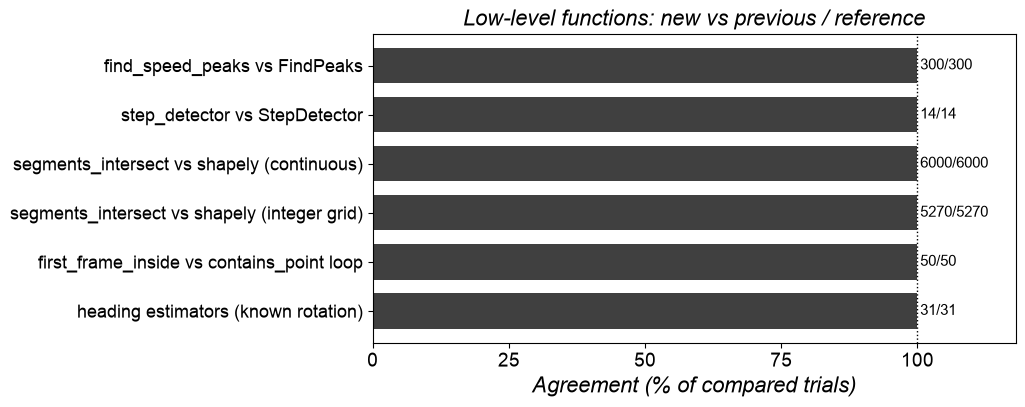

In [4]:
def bumpy_curve(n=800):
    """Random positive speed-like curve: 4 Gaussian bumps + noise.

    Parameters
    ----------
    n : int, optional
        Number of samples.

    Returns
    -------
    numpy.ndarray, shape (n,)
    """
    tt = np.arange(n)
    c = sum(RNG.uniform(0.2, 1.5) * np.exp(-0.5 * ((tt - RNG.uniform(0, n)) / RNG.uniform(5, 40)) ** 2) for _ in range(4))
    return np.abs(c + 0.01 * RNG.standard_normal(n))


results = {}
# FindPeaks
ok = []
for _ in range(300):
    c = bumpy_curve(); vmax = c.max(); args = (0.3 * vmax, 0.1 * vmax, 0.01 * vmax)
    ok.append(kinematics.find_speed_peaks(c, *args) == ref.FindPeaks(list(c), *args))
results["find_speed_peaks vs FindPeaks"] = ok
# StepDetector
cases = {k: synthetic.synthetic_trial(**kw) for k, kw in synthetic.SCENARIOS.items()}
cases["no step"] = synthetic.synthetic_trial()
cases["abduction"] = synthetic.synthetic_trial("R", (0.15, 0.0), abduction=True)
ok = []
for tr in cases.values():
    for exc in (False, True):
        a = kinematics.step_detector(tr["RTOE"], tr["LTOE"], exception=exc)
        b = ref.StepDetector(tr["RTOE"], tr["LTOE"], config.DT, exception=exc)
        ok.append(a[0] == b[0] and [list(map(int, s)) for s in a[1]] == [list(map(int, s)) for s in b[1]])
results["step_detector vs StepDetector"] = ok
# Segment intersection
for name, grid in (("continuous", None), ("integer grid", 4)):
    p = RNG.integers(0, grid, (6000, 8)).astype(float) if grid else RNG.uniform(0, 1, (6000, 8))
    p = p[(np.hypot(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1]) > 0) & (np.hypot(p[:, 6] - p[:, 4], p[:, 7] - p[:, 5]) > 0)]
    new_i = geometry.segments_intersect(p[:, 0:2], p[:, 2:4], p[:, 4:6], p[:, 6:8])
    old_i = np.array([LineString([r[0:2], r[2:4]]).intersects(LineString([r[4:6], r[6:8]])) for r in p])
    results[f"segments_intersect vs shapely ({name})"] = list(new_i == old_i)
# Polygon containment
ok = []
for _ in range(50):
    poly = np.array(list(synthetic.RIGHT_FOOT.values())) + RNG.normal(0, 0.01, (4, 2))
    pts = RNG.uniform(-0.2, 0.3, (400, 2))
    loop = next((i for i, q in enumerate(pts) if MplPath(poly).contains_point(q)), None)
    ok.append(geometry.first_frame_inside(poly, pts) == loop)
results["first_frame_inside vs contains_point loop"] = ok
# Heading estimators
ok = []
for h in np.linspace(-15, 15, 31):
    tr = synthetic.synthetic_trial(heading_deg=h)
    ok.append(abs(geometry.heading_angle(geometry.heading_from_feet(tr, 100)) - h) < 1e-9
              and abs(geometry.heading_angle(geometry.heading_from_shoulders(tr, 100)) - h) < 1e-9)
results["heading estimators (known rotation)"] = ok

pct = [100 * np.mean(v) for v in results.values()]
ann = {"agreement": [f"{sum(v)}/{len(v)}" for v in results.values()]}
fig, ax = plt.subplots(figsize=(style.FIG_WIDTH * 1.3, 0.7 * style.FIG_HEIGHT))
figures.plot_agreement(ax, list(results), {"agreement": pct}, annotations=ann)
style.set_labels(ax, title="Low-level functions: new vs previous / reference", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

### 1.4 Unified classification on synthetic trials with a known label

Each scenario is built so that one rule of the flowchart (manuscript Fig. 2.12) decides the label:
- the CoM moves to the left onto the non-stepping foot → UMS;
- the CoM moves onto the stepping foot → LSS;
- the feet cross → UCS;
- the CoM crosses the toes line → FS;
- the CoM stays between the feet → SCS.

Each panel shows:
- the feet at t_begin (stepping foot dashed) and at t_end (grey);
- the front boundary (red dotted);
- the CoM path, purple after t_begin;
- the step vector (arrow);
- the frame that decided the label (star).

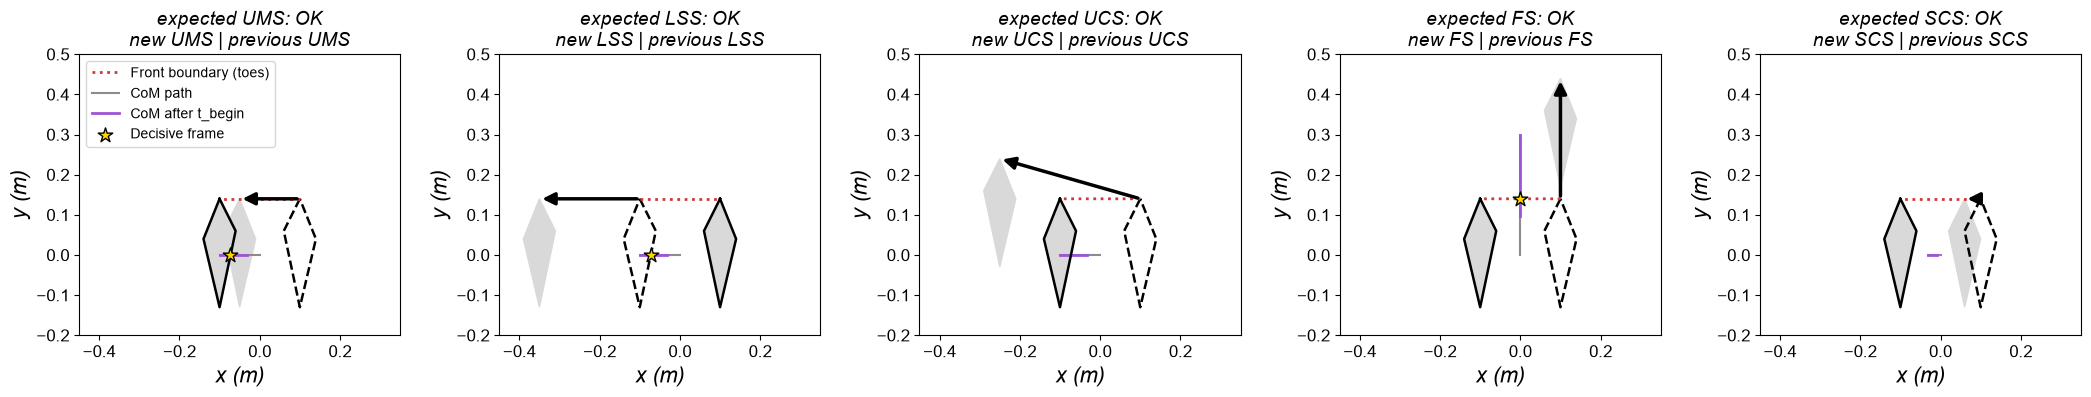

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(2.6 * style.FIG_WIDTH, 0.75 * style.FIG_HEIGHT))
for ax, (label, kw) in zip(axes, synthetic.SCENARIOS.items()):
    tr = synthetic.synthetic_trial(**kw)
    feet, steps = kinematics.step_detector(tr["RTOE"], tr["LTOE"])
    res = classification.unified_classification(tr, feet[0], *steps[0])
    old = ref.FirstStepBlock(*(tr[k] for k in ("RTOE", "RTARI", "RHEE", "RTAR", "LTOE", "LTARI", "LHEE", "LTAR", "COM")))
    mark = "OK" if res.label == label == old["UnifiedClassifStepName"] else "MISMATCH"
    figures.plot_top_view(ax, tr, feet[0], *steps[0], result=res,
                        title=f"expected {label}: {mark}\nnew {res.label} | previous {old['UnifiedClassifStepName']}")
    ax.set_xlim(-0.45, 0.35); ax.set_ylim(-0.2, 0.5)
axes[0].legend(fontsize=style.FONT_SIZE - 10, loc="upper left")
fig.tight_layout(); plt.show()

## 2. Same functions as before, on the real data

The previous first-step block of `CreateAllQtyDF` (step detection, crossover test, Unified classification, step vector, projection on the CoM velocity) is copied as a reference in `src/step_analysis/validation/previous_code.py`. It is run alongside the new code on **every open-data trial with a step**.
- Detection runs in exception mode for the 90° pushes, as in `GenerateStepDataframe`.
- The comparison also times the two implementations. Data loading is excluded from the timing.

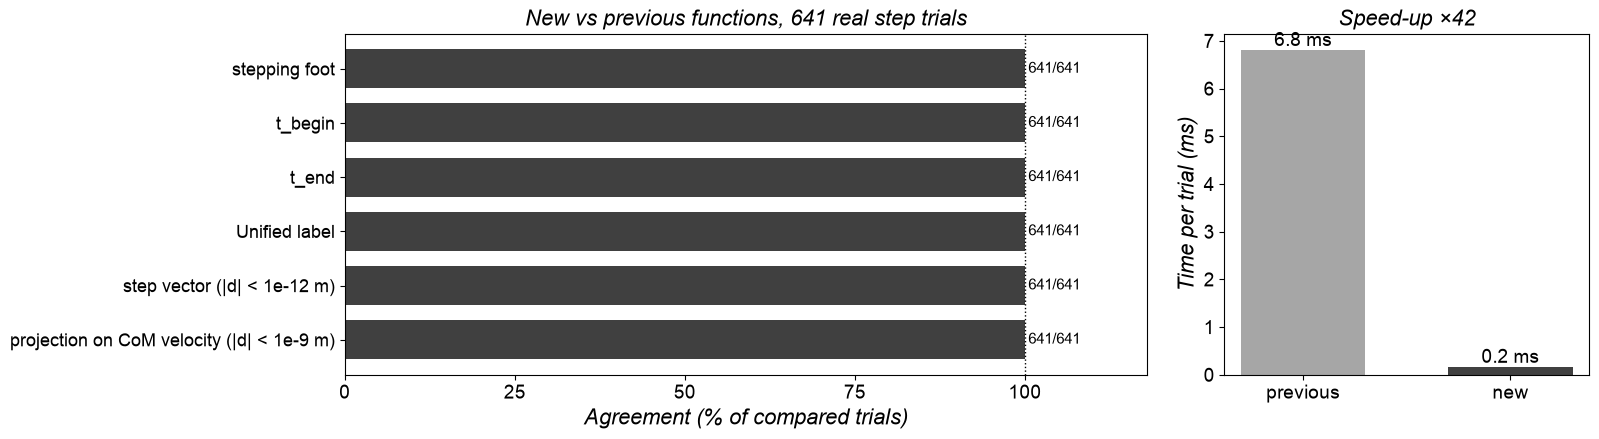

In [6]:
open_table = pipeline.build_first_step_table(cache_file=None)  # fresh computation from the raw CSV files
step_rows = open_table[open_table["step_index"] == 2]
names = ["stepping foot", "t_begin", "t_end", "Unified label", "step vector (|d| < 1e-12 m)",
         "projection on CoM velocity (|d| < 1e-9 m)"]
agree = {n: [] for n in names}
t_old = t_new = 0.0
MARKERS = ("RTOE", "RTARI", "RHEE", "RTAR", "LTOE", "LTARI", "LHEE", "LTAR", "COM")
for row in step_rows.itertuples():
    tr = data_io.load_trial(row.participant, row.condition, row.push_folder)
    exc = data_io.instructed_angle(row.push_folder) == "90"
    t0 = time.perf_counter()
    old = ref.FirstStepBlock(*(tr[k] for k in MARKERS), exception=exc)
    t_old += time.perf_counter() - t0
    t0 = time.perf_counter()
    feet, steps = kinematics.step_detector(tr["RTOE"], tr["LTOE"], exception=exc)
    res = classification.unified_classification(tr, feet[0], *steps[0])
    vec = geometry.step_vector(tr[feet[0] + "TOE"], *steps[0])
    kinematics.temporal_deriv(tr["COM"][:2])
    t_new += time.perf_counter() - t0
    agree["stepping foot"].append(old["SteppingFoot"] == feet[0])
    agree["t_begin"].append(old["FirstStepBegIndex"] == steps[0][0])
    agree["t_end"].append(old["FirstStepEndIndex"] == steps[0][1])
    agree["Unified label"].append(old["UnifiedClassifStepName"] == res.label)
    agree["step vector (|d| < 1e-12 m)"].append(np.allclose(old["StepVector"], vec, rtol=0, atol=1e-12))
    agree[names[5]].append(abs(old["StepLength_xVcomRef"] - row.step_length_x_vcom_ref) < 1e-9
                           and abs(old["StepLength_yVcomRef"] - row.step_length_y_vcom_ref) < 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, 0.75 * style.FIG_HEIGHT), gridspec_kw=dict(width_ratios=[2.2, 1]))
figures.plot_agreement(axes[0], names, {"agreement": [100 * np.mean(v) for v in agree.values()]},
                     annotations={"agreement": [f"{sum(v)}/{len(v)}" for v in agree.values()]})
style.set_labels(axes[0], title=f"New vs previous functions, {len(step_rows)} real step trials", fontsize=style.FONT_SIZE - 4)
ms = [1000 * t_old / len(step_rows), 1000 * t_new / len(step_rows)]
axes[1].bar(["previous", "new"], ms, color=["0.65", "0.25"], width=0.6)
for i, v in enumerate(ms):
    axes[1].text(i, v, f"{v:.1f} ms", ha="center", va="bottom", fontsize=style.FONT_SIZE - 6)
axes[1].tick_params(labelsize=style.FONT_SIZE - 6)
style.set_labels(axes[1], ylabel="Time per trial (ms)", title=f"Speed-up ×{ms[0] / ms[1]:.0f}", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

## 3. Cross-validation against the saved previous results

The new pipeline (`pipeline.build_first_step_table`) is compared with `AllQtyDF.csv` and `StepDataframe.csv` on two inputs:
- **the raw files used by the previous analysis** (`Previous works/DeCIMo/Data_DeCIMo`). This tests the code alone: everything should match.
- **the open data** (`data/DeCIMo_OpenSource_data`), the input of this project.

Exact agreement is required for indices and labels. Float quantities must agree within $10^{-9}$ (their unit).

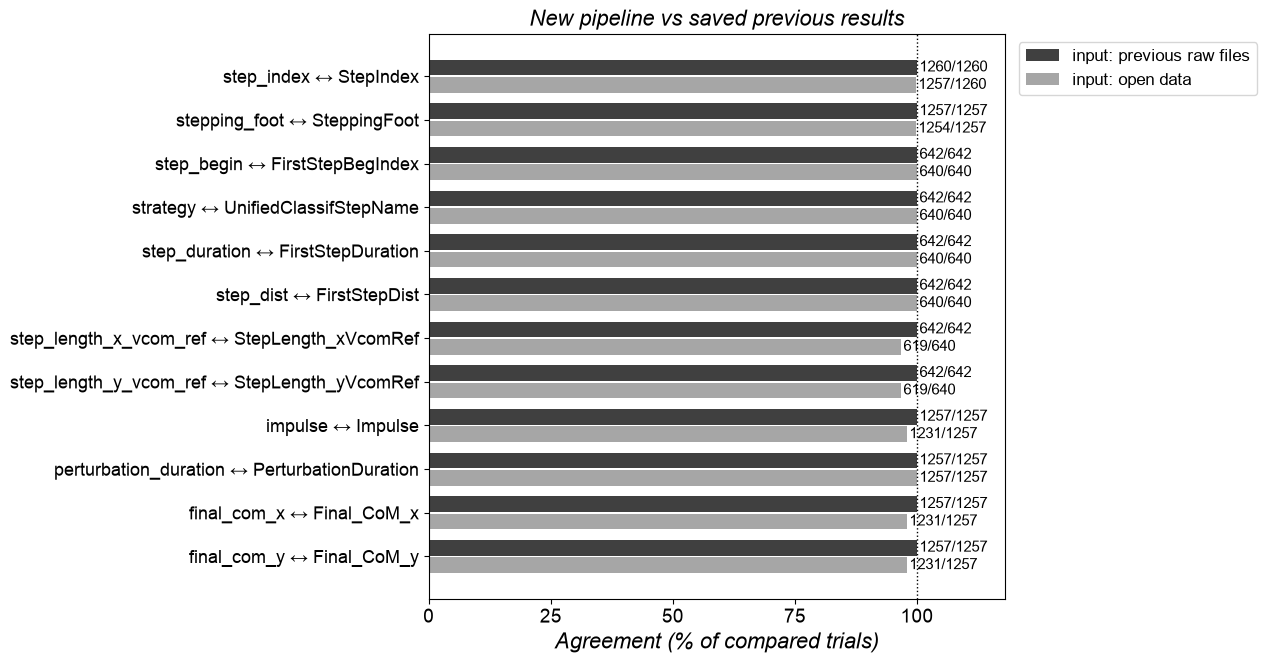

Discarded 'no push' trials, new: [('S0', 'SI', 'PL0_1'), ('S15', 'SI', 'PH90_1'), ('S15', 'SI', 'PL180_1')]
Trials absent from AllQtyDF.csv: [('S0', 'SI', 'PL0_1'), ('S15', 'SI', 'PH90_1'), ('S15', 'SI', 'PL180_1')]


previous raw files                       open data  \
                               n_compared n_match max_abs_diff n_compared   
quantity                                                                    
step_index                           1260    1260          NaN       1260   
stepping_foot                        1257    1257          NaN       1257   
step_begin                            642     642          NaN        640   
strategy                              642     642          NaN        640   
step_duration                         642     642    0.000e+00        640   
step_dist                             642     642    1.110e-16        640   
step_length_x_vcom_ref                642     642    0.000e+00        640   
step_length_y_vcom_ref                642     642    0.000e+00        640   
impulse                              1257    1257    7.105e-14       1257   
perturbation_duration                1257    1257    0.000e+00       1257   
final_com_x                          1257    1257    0.000e+00       1257   
final_com_y                          1257    1257    0.000e+00       1257   

                                             
                       n_match max_abs_diff  
quantity                                     
step_index                1257          NaN  
stepping_foot             1254          NaN  
step_begin                 640          NaN  
strategy                   640          NaN  
step_duration              640    0.000e+00  
step_dist                  640    1.110e-15  
step_length_x_vcom_ref     619    3.873e-03  
step_length_y_vcom_ref     619    2.271e-02  
impulse                   1231    8.343e-01  
perturbation_duration     1257    0.000e+00  
final_com_x               1231    4.096e-01  
final_com_y               1231    5.139e-01

In [7]:
if not HAS_PREVIOUS:
    raise RuntimeError("Previous analysis files not found: set DECIMO_PREVIOUS_DIR / DECIMO_PREVIOUS_RAW_DIR")
prev_table = pipeline.build_first_step_table(cache_file=None, loader=previous_results.load_previous_raw_trial)
_, sum_prev, mism_prev, sets_prev = previous_results.compare_with_previous(prev_table)
merged_open, sum_open, mism_open, sets_open = previous_results.compare_with_previous(open_table)

labels = [f"{a} ↔ {b}" for a, b in zip(sum_prev["quantity"], sum_prev["previous"])]
fig, ax = plt.subplots(figsize=(style.FIG_WIDTH * 1.6, 1.1 * style.FIG_HEIGHT))
figures.plot_agreement(
    ax, labels,
    {"input: previous raw files": sum_prev["match_pct"], "input: open data": sum_open["match_pct"]},
    annotations={"input: previous raw files": [f"{m}/{n}" for m, n in zip(sum_prev.n_match, sum_prev.n_compared)],
                 "input: open data": [f"{m}/{n}" for m, n in zip(sum_open.n_match, sum_open.n_compared)]})
style.set_labels(ax, title="New pipeline vs saved previous results", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

print("Discarded 'no push' trials, new:", sets_prev["no_push"])
print("Trials absent from AllQtyDF.csv:", sets_prev["missing_in_previous"])
pd.concat({"previous raw files": sum_prev.set_index("quantity")[["n_compared", "n_match", "max_abs_diff"]],
           "open data": sum_open.set_index("quantity")[["n_compared", "n_match", "max_abs_diff"]]}, axis=1)

**Result on the previous raw files.** All quantities agree in 100 % of the trials, including the 3 discarded "no push" trials. The largest float difference is ~$10^{-13}$, which is floating-point rounding. The code reproduces the previous analysis.

**Result on the open data.** The mismatches all come from trials whose open-data files differ from the files used before (next cell). Strategy labels, as stored in `AllQtyDF.csv`, compared with the labels computed on the open data:

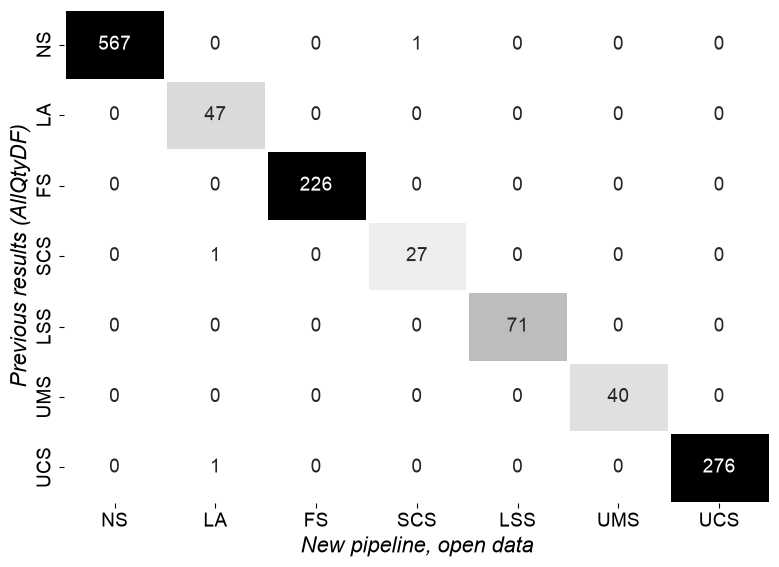

3 trial(s) off the diagonal out of 1257


In [8]:
order = ["NS", "LA", "FS", "SCS", "LSS", "UMS", "UCS"]
lab = merged_open.dropna(subset=["prev_UnifiedClassifStepName"])
cm = pd.crosstab(lab["prev_UnifiedClassifStepName"], lab["strategy"]).reindex(index=order, columns=order, fill_value=0)
fig, ax = plt.subplots(figsize=(style.FIG_WIDTH, 0.95 * style.FIG_HEIGHT))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greys", cbar=False, linewidths=1, linecolor="white",
            annot_kws=dict(fontsize=style.FONT_SIZE - 6), ax=ax, vmax=cm.values.max() / 3)
ax.tick_params(labelsize=style.FONT_SIZE - 6)
style.set_labels(ax, "New pipeline, open data", "Previous results (AllQtyDF)", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()
off = cm.values.sum() - np.trace(cm.values)
print(f"{off} trial(s) off the diagonal out of {cm.values.sum()}")

### 3.1 Differences between the open data and the files used before

`previous_results.compare_raw_data` compares the CSV files (COM, toes, force) of every trial in both datasets.

26 of 1260 trials differ; previous version shorter in all of them: True


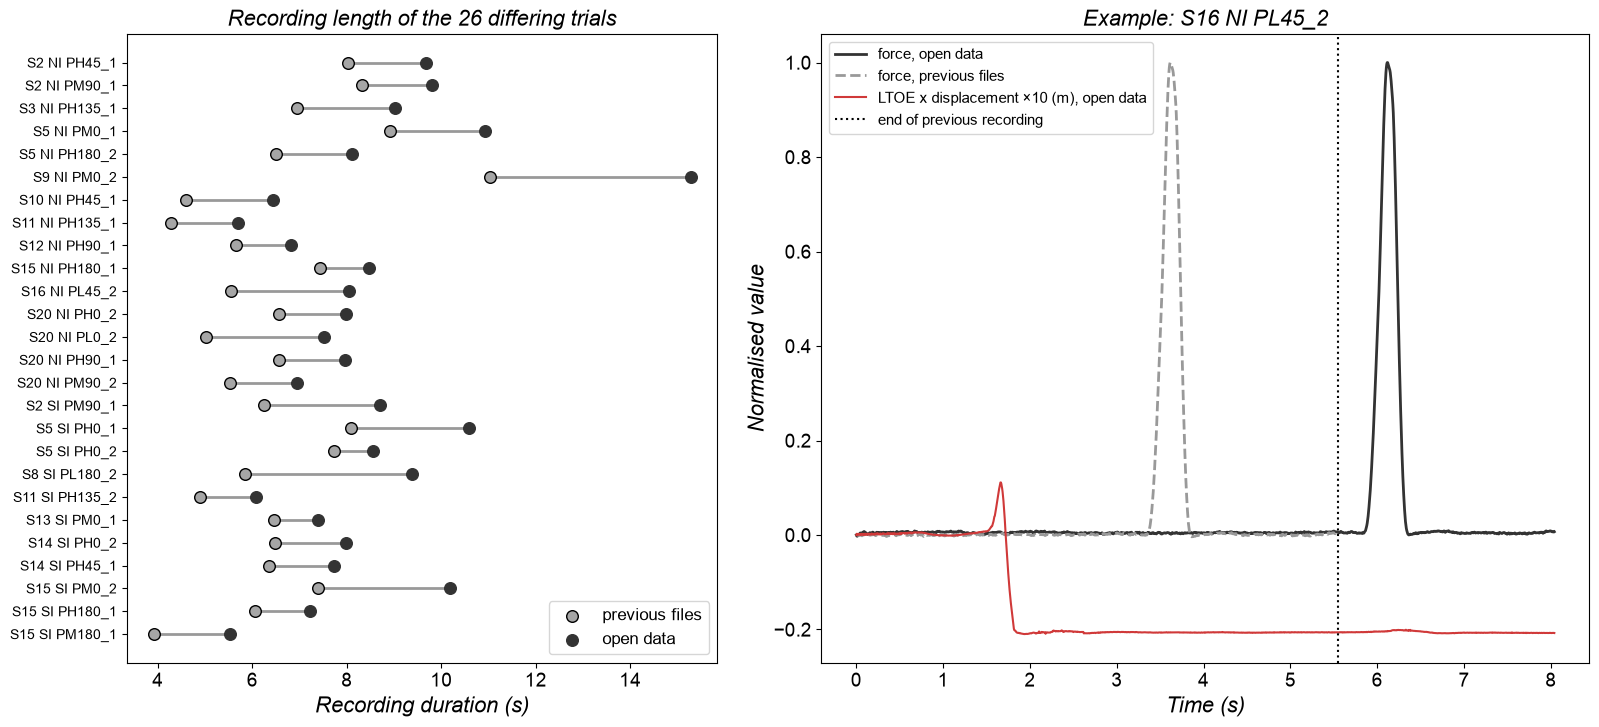

In [9]:
raw_diff = previous_results.compare_raw_data()
updated = raw_diff[~raw_diff["identical"]].copy()
print(f"{len(updated)} of {len(raw_diff)} trials differ; previous version shorter in all of them: "
      f"{(updated.n_frames_open > updated.n_frames_previous).all()}")
assert set(zip(updated.participant, updated.condition, updated.push_folder)) == set(previous_results.UPDATED_TRIALS)

updated["trial"] = updated["participant"] + " " + updated["condition"] + " " + updated["push_folder"]
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, 1.2 * style.FIG_HEIGHT), gridspec_kw=dict(width_ratios=[1, 1.3]))
ax = axes[0]
y = np.arange(len(updated))[::-1]
ax.hlines(y, updated.n_frames_previous * config.DT, updated.n_frames_open * config.DT, color="0.6", lw=2)
ax.scatter(updated.n_frames_previous * config.DT, y, color="0.65", edgecolors="k", s=70, zorder=3, label="previous files")
ax.scatter(updated.n_frames_open * config.DT, y, color="0.2", s=70, zorder=3, label="open data")
ax.set_yticks(y); ax.set_yticklabels(updated["trial"], fontsize=style.FONT_SIZE - 10)
ax.tick_params(axis="x", labelsize=style.FONT_SIZE - 6)
ax.legend(fontsize=style.FONT_SIZE - 8, loc="lower right")
style.set_labels(ax, xlabel="Recording duration (s)", title="Recording length of the 26 differing trials", fontsize=style.FONT_SIZE - 4)

# Example: a trial whose force signal was also re-aligned in the previous files
ex = ("S16", "NI", "PL45_2")
a = data_io.load_trial(*ex, markers=("COM", "ForceSensor", "LTOE"))
b = previous_results.load_previous_raw_trial(*ex, markers=("COM", "ForceSensor", "LTOE"))
ax = axes[1]
ta, tb = np.arange(a["COM"].shape[1]) * config.DT, np.arange(b["COM"].shape[1]) * config.DT
ax.plot(ta, a["ForceSensor"] / a["ForceSensor"].max(), color="0.2", lw=2, label="force, open data")
ax.plot(tb, b["ForceSensor"] / b["ForceSensor"].max(), color="0.6", lw=2, ls="--", label="force, previous files")
ax.plot(ta, 10 * (a["LTOE"][0] - a["LTOE"][0, 0]), color="#D03939", lw=1.5, label="LTOE x displacement ×10 (m), open data")
ax.axvline(tb[-1], color="k", ls=":", lw=1.5, label="end of previous recording")
ax.legend(fontsize=style.FONT_SIZE - 9, loc="upper left")
ax.tick_params(labelsize=style.FONT_SIZE - 6)
style.set_labels(ax, "Time (s)", "Normalised value", f"Example: {' '.join(ex)}", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

Impact on the first-step table: trials where the open data change the detection, the label or the step vector compared with the previous files.

In [10]:
k = ["participant", "condition", "push"]
cmp = open_table.merge(prev_table, on=k, suffixes=("_open", "_previous"))
changed = cmp[(cmp.strategy_open != cmp.strategy_previous)
              | ~np.isclose(cmp.ml_pct_open.fillna(0), cmp.ml_pct_previous.fillna(0), atol=1e-9)
              | ~np.isclose(cmp.ap_pct_open.fillna(0), cmp.ap_pct_previous.fillna(0), atol=1e-9)]
changed[k + ["strategy_previous", "strategy_open", "step_begin_previous", "step_begin_open",
             "perturbation_start_previous", "perturbation_start_open"]]

,participant,condition,push,strategy_previous,strategy_open,step_begin_previous,step_begin_open,perturbation_start_previous,perturbation_start_open
491,S16,NI,PL45_2,NS,SCS,<NA>,311,665,1165
899,S8,SI,PL180_2,SCS,LA,883,<NA>,783,783
1083,S15,SI,PM0_2,UCS,LA,1132,<NA>,989,989


**Consequences.**
- Only 3 trials change at the level of the first step:
  - S16 NI PL45_2: previously no step. In the open data it has an SCS-labelled "step" at frame 311, long before the push. The open-data force signal is shifted by about 500 frames (example above).
  - S8 SI PL180_2: SCS before, leg abduction now.
  - S15 SI PM0_2: UCS before, leg abduction now.
- For the strategies analysed in `01_First_Step_Decomposition.ipynb` (UMS, LSS, UCS), only S15 SI PM0_2 (one UCS) is lost. All other UMS / LSS / UCS step vectors are identical in both datasets.
- In the 23 other differing trials, the first step itself is unchanged, but the end of the recording differs. That changes `Final_CoM`, the impulse (its zero offset is the last force value) and, slightly, the CoM velocity.

The open-source dataset should probably be updated with the trimmed versions of these 26 trials.

## 4. Visual check on real trials

For each strategy, the trial closest to the strategy median (in the stepping-leg ML / AP plane):
- left: step detection signals (all normalised by their maximum, push shaded);
- right: top view, same elements as §1.4.

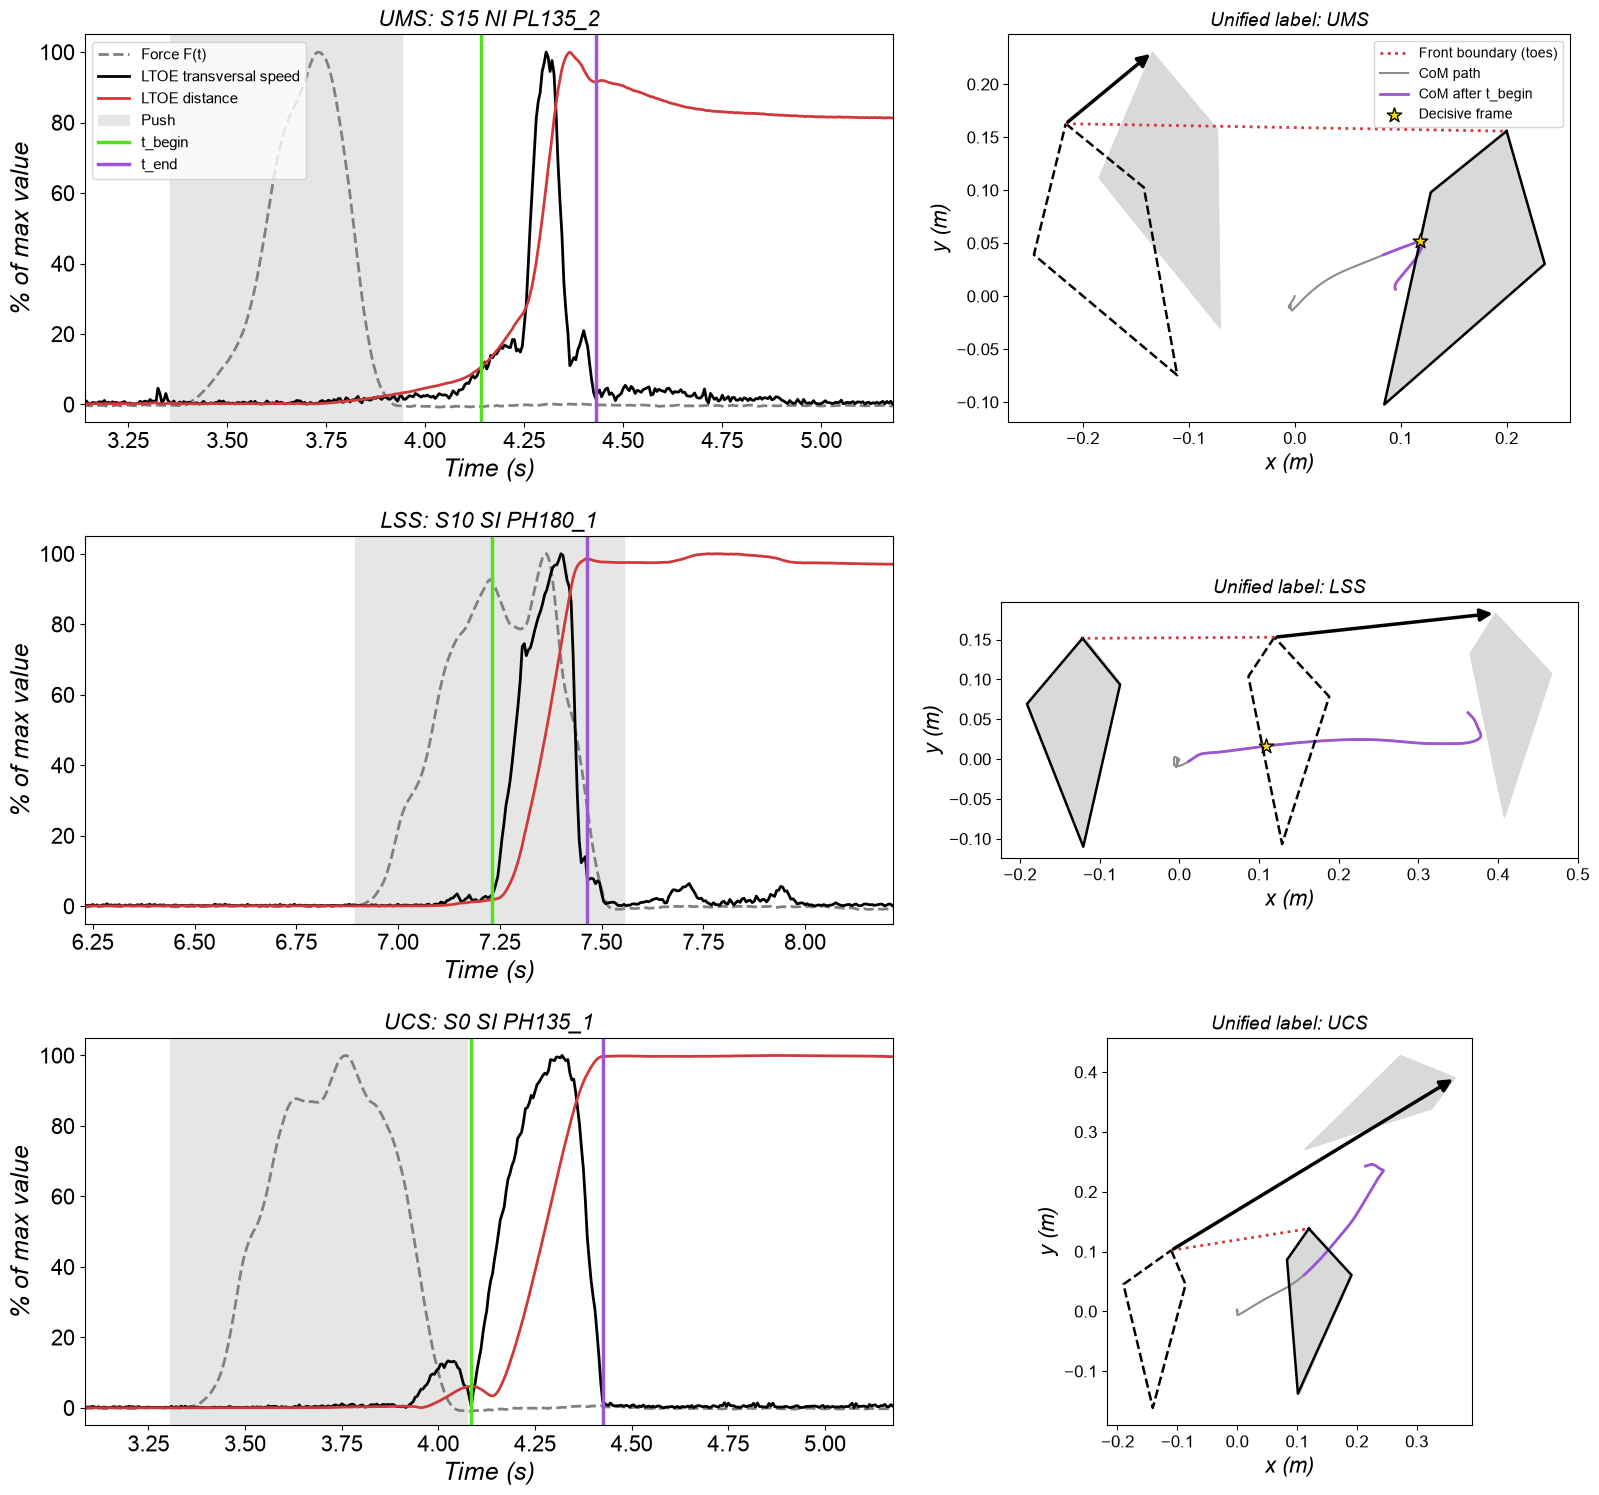

In [11]:
sel = pipeline.select_first_steps(open_table)
fig, axes = plt.subplots(3, 2, figsize=(2 * style.FIG_WIDTH, 2.4 * style.FIG_HEIGHT), gridspec_kw=dict(width_ratios=[1.4, 1]))
for (ax_t, ax_v), s in zip(axes, style.STRATEGY_ORDER):
    g = sel[sel.strategy == s]
    med = g[["ml_lateral_pct", "ap_pct"]].median()
    row = g.loc[((g[["ml_lateral_pct", "ap_pct"]] - med) ** 2).sum(axis=1).idxmin()]
    tr = data_io.load_trial(row.participant, row.condition, row.push_folder)
    exc = data_io.instructed_angle(row.push_folder) == "90"
    feet, steps, diag = kinematics.step_detector(tr["RTOE"], tr["LTOE"], exception=exc, return_diagnostics=True)
    figures.plot_step_detection(ax_t, tr, diag, steps, feet, perturbation=(row.perturbation_start, row.perturbation_end))
    b, e = int(row.step_begin), int(row.step_end)
    ax_t.set_xlim(max(0, b - 200) * config.DT, (e + 150) * config.DT)
    style.set_labels(ax_t, title=f"{s}: {row.participant} {row.condition} {row.push}", fontsize=style.FONT_SIZE - 4)
    res = classification.unified_classification(tr, row.stepping_foot, b, e)
    figures.plot_top_view(ax_v, tr, row.stepping_foot, b, e, result=res, title=f"Unified label: {res.label}")
axes[0, 0].legend(fontsize=style.FONT_SIZE - 9, loc="upper left")
axes[0, 1].legend(fontsize=style.FONT_SIZE - 10, loc="best")
fig.tight_layout(); plt.show()

## 5. Lab axes as an approximation of the participant's ML / AP axes

The main analysis uses lab x as ML (+ right) and lab y as AP (+ forward). Participants were asked to stand aligned with these axes. To test the approximation, the participant's real forward direction is estimated **at perturbation initiation**: markers are averaged over the 0.1 s ending at the push onset found from the force sensor. Two estimators are used:
- **feet**: unit vector from the mid-heels point to the mid-toes point;
- **shoulders**: horizontal normal to the left-to-right shoulder vector (the reference used for angles in the manuscript).

The heading is the angle between this direction and lab +y (positive = turned towards the right).

### 5.1 Heading at perturbation initiation

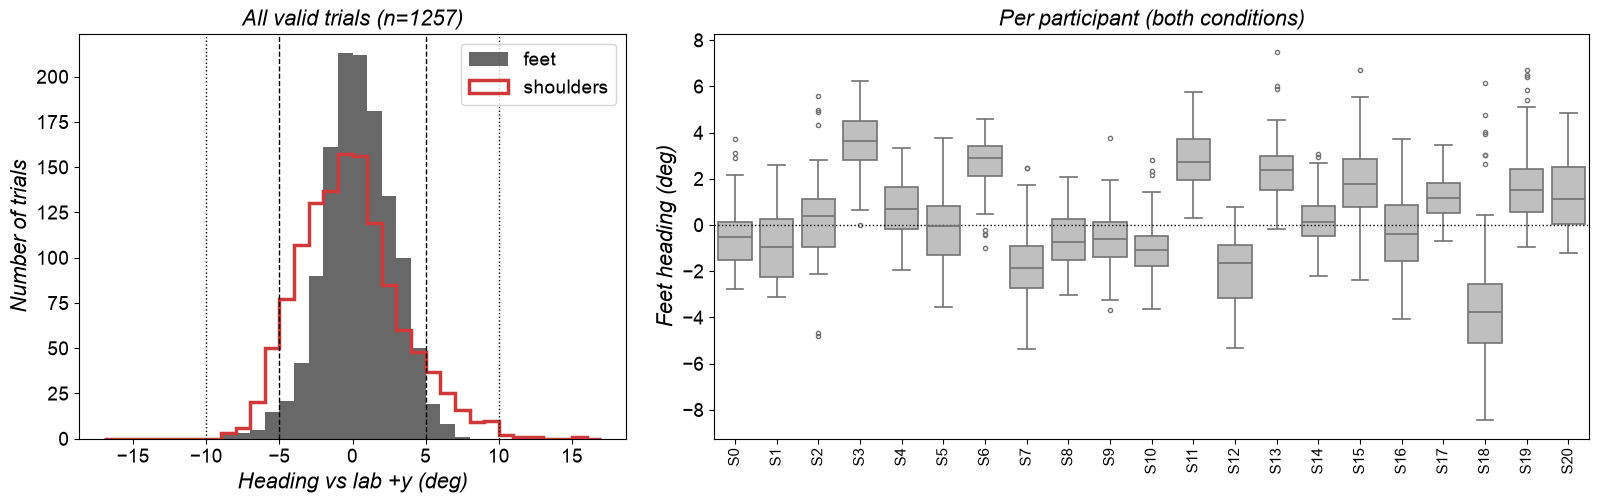

,mean,SD,95th pct of |heading|,max |heading|,n > 5 deg,n > 10 deg
heading_feet_deg,0.371,2.376,4.855,8.451,53.0,0.0
heading_shoulders_deg,-0.147,3.424,6.586,15.641,181.0,5.0


In [12]:
valid = open_table[~open_table["no_push"].astype(bool)]
fig, axes = plt.subplots(1, 2, figsize=(2 * style.FIG_WIDTH, 0.85 * style.FIG_HEIGHT), gridspec_kw=dict(width_ratios=[1, 1.6]))
ax = axes[0]
bins = np.arange(-17, 17.5, 1)
ax.hist(valid["heading_feet_deg"], bins=bins, color="0.3", alpha=0.85, label="feet")
ax.hist(valid["heading_shoulders_deg"], bins=bins, histtype="step", color="#D03939", lw=2.5, label="shoulders")
for v, ls in ((5, "--"), (10, ":")):
    ax.axvline(v, color="k", ls=ls, lw=1); ax.axvline(-v, color="k", ls=ls, lw=1)
ax.legend(fontsize=style.FONT_SIZE - 6)
ax.tick_params(labelsize=style.FONT_SIZE - 6)
style.set_labels(ax, "Heading vs lab +y (deg)", "Number of trials", f"All valid trials (n={len(valid)})", fontsize=style.FONT_SIZE - 4)

ax = axes[1]
order_p = [f"S{i}" for i in range(21)]
sns.boxplot(data=valid, x="participant", y="heading_feet_deg", order=order_p, color="0.75", fliersize=3, linewidth=1.2, ax=ax)
ax.axhline(0, color="k", lw=1, ls=":")
ax.tick_params(axis="x", labelsize=style.FONT_SIZE - 9, rotation=90)
ax.tick_params(axis="y", labelsize=style.FONT_SIZE - 6)
style.set_labels(ax, "", "Feet heading (deg)", "Per participant (both conditions)", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

heading_stats = pd.DataFrame({
    c: {"mean": valid[c].mean(), "SD": valid[c].std(), "95th pct of |heading|": np.percentile(np.abs(valid[c]), 95),
        "max |heading|": np.abs(valid[c]).max(), "n > 5 deg": int((np.abs(valid[c]) > 5).sum()),
        "n > 10 deg": int((np.abs(valid[c]) > 10).sum())}
    for c in ("heading_feet_deg", "heading_shoulders_deg")}).T
heading_stats

### 5.2 Effect on the decomposition of the lateral first steps

For every UMS / LSS / UCS first step, the step vector is decomposed twice: in the lab axes and in the participant frame (feet or shoulders). A rotation by the heading angle θ changes the components by at most $|\vec{s}|\,2\sin(\theta/2) \approx |\vec{s}|\,\theta$.

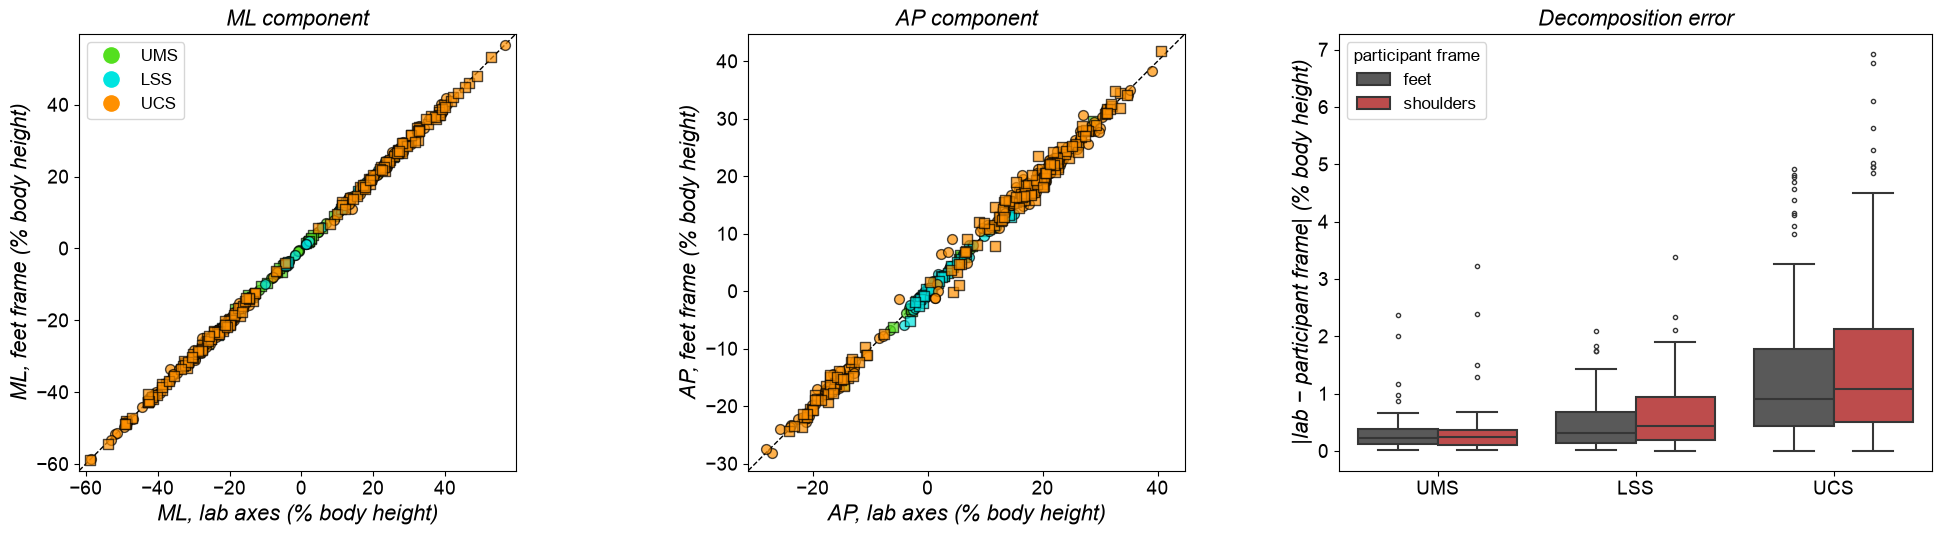

feet                      shoulders                     
          count    50%    95%    max     count    50%    95%    max
strategy                                                           
UMS        40.0  0.222  1.206  2.369      40.0  0.239  1.549  3.221
LSS        71.0  0.309  1.586  2.088      71.0  0.439  1.877  3.390
UCS       276.0  0.906  3.222  4.910     276.0  1.075  4.166  6.928

In [13]:
err = {}
for f in ("feet", "shoulders"):
    d_ml = sel[f"ml_{f}_pct"] - sel["ml_pct"]
    d_ap = sel[f"ap_{f}_pct"] - sel["ap_pct"]
    err[f] = pd.DataFrame({"strategy": sel["strategy"], "d_ml": d_ml, "d_ap": d_ap, "error": np.hypot(d_ml, d_ap)})

fig, axes = plt.subplots(1, 3, figsize=(2.5 * style.FIG_WIDTH, 0.9 * style.FIG_HEIGHT))
for ax, (lab_col, part_col, name) in zip(axes[:2], (("ml_pct", "ml_feet_pct", "ML"), ("ap_pct", "ap_feet_pct", "AP"))):
    style.scatter_strategies(ax, sel, lab_col, part_col, s=50)
    lim = [min(sel[lab_col].min(), sel[part_col].min()) - 3, max(sel[lab_col].max(), sel[part_col].max()) + 3]
    ax.plot(lim, lim, color="k", lw=1, ls="--", zorder=0)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.tick_params(labelsize=style.FONT_SIZE - 6)
    style.set_labels(ax, f"{name}, lab axes (% body height)", f"{name}, feet frame (% body height)", f"{name} component", fontsize=style.FONT_SIZE - 4)
axes[0].legend(style.strategy_handles(), style.STRATEGY_ORDER, fontsize=style.FONT_SIZE - 8, loc="upper left")

both = pd.concat({"feet": err["feet"], "shoulders": err["shoulders"]}).reset_index(level=0, names="frame")
sns.boxplot(data=both, x="strategy", y="error", hue="frame", order=style.STRATEGY_ORDER, palette=["0.35", "#D03939"],
            fliersize=3, linewidth=1.5, ax=axes[2])
axes[2].tick_params(labelsize=style.FONT_SIZE - 6)
axes[2].legend(title="participant frame", fontsize=style.FONT_SIZE - 8, title_fontsize=style.FONT_SIZE - 8)
style.set_labels(axes[2], "", "|lab − participant frame| (% body height)", "Decomposition error", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

pd.concat({f: e.groupby("strategy")["error"].describe(percentiles=[0.5, 0.95])[["count", "50%", "95%", "max"]]
           .loc[style.STRATEGY_ORDER] for f, e in err.items()}, axis=1)

### 5.3 Acceptance criteria

The approximation is accepted for this descriptive analysis if all of the following hold:
- **C1.** The participant heading stays within ±10° of the lab axes in every valid trial. At 10°, cross-talk between the axes is sin 10° ≈ 17 % of the step length.
- **C2.** No step changes medial/lateral side (sign of the ML component).
- **C3.** For each strategy, the 95th percentile of the decomposition error is smaller than the inter-quartile range of both the ML and the AP component of that strategy. The approximation is then much smaller than the natural spread of the data.
- **C4.** The median ML and AP of each strategy move by less than 1 % body height (≈ 1.7 cm).

C3 and C4 use the ML component in the stepping-leg frame. In the anatomical frame, left-foot and right-foot steps form mirrored clusters, which would inflate the IQR and make the median meaningless. The decomposition error itself does not depend on this mirroring.

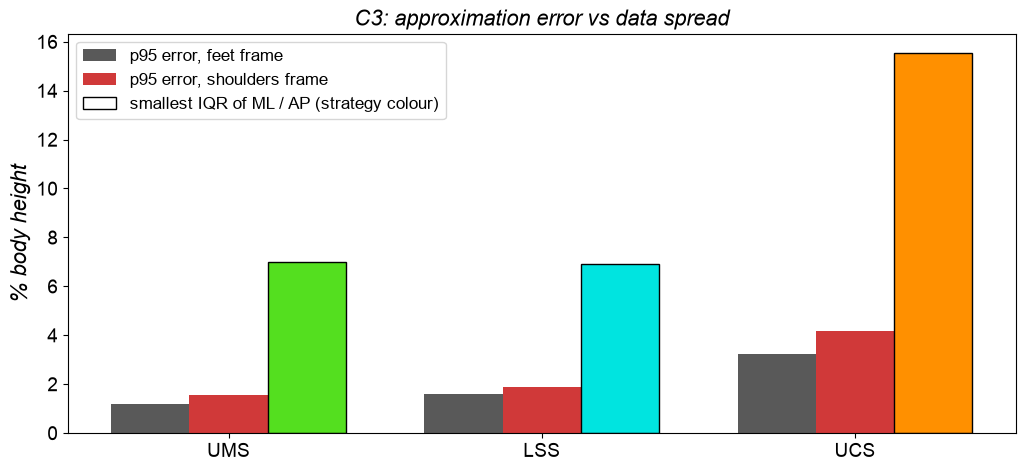

     feet frame: all criteria pass
shoulders frame: failed: C1 max |heading| (deg)


value  threshold  passed
frame     criterion                                                        
feet      C1 max |heading| (deg)                   8.451     10.000    True
          C2 ML side changes (n steps)             0.000      0.000    True
          C3 UMS: p95 error < min IQR (% height)   1.206      7.003    True
          C4 UMS: median shift (% height)          0.202      1.000    True
          C3 LSS: p95 error < min IQR (% height)   1.586      6.895    True
          C4 LSS: median shift (% height)          0.231      1.000    True
          C3 UCS: p95 error < min IQR (% height)   3.222     15.547    True
          C4 UCS: median shift (% height)          0.221      1.000    True
shoulders C1 max |heading| (deg)                  15.641     10.000   False
          C2 ML side changes (n steps)             0.000      0.000    True
          C3 UMS: p95 error < min IQR (% height)   1.549      7.003    True
          C4 UMS: median shift (% height)          0.245      1.000    True
          C3 LSS: p95 error < min IQR (% height)   1.877      6.895    True
          C4 LSS: median shift (% height)          0.442      1.000    True
          C3 UCS: p95 error < min IQR (% height)   4.166     15.547    True
          C4 UCS: median shift (% height)          0.253      1.000    True

In [14]:
def iqr(v):
    """Inter-quartile range of a 1D array-like (same unit as the values)."""
    return np.subtract(*np.percentile(v, [75, 25]))


side = geometry.lateral_sign(sel["stepping_foot"])  # +1 right-foot step, -1 left-foot step
rows = []
for f in ("feet", "shoulders"):
    head = valid[f"heading_{f}_deg"].abs().max()
    rows.append(dict(frame=f, criterion="C1 max |heading| (deg)", value=head, threshold=10, passed=head <= 10))
    flips = int((np.sign(sel[f"ml_{f}_pct"]) != np.sign(sel["ml_pct"])).sum())
    rows.append(dict(frame=f, criterion="C2 ML side changes (n steps)", value=flips, threshold=0, passed=flips == 0))
    ml_lat_part = sel[f"ml_{f}_pct"] * side  # stepping-leg ML in the participant frame
    for s in style.STRATEGY_ORDER:
        m = (sel.strategy == s).to_numpy()
        g, e = sel[m], err[f][err[f].strategy == s]["error"]
        p95, spread = np.percentile(e, 95), min(iqr(g["ml_lateral_pct"]), iqr(g["ap_pct"]))
        rows.append(dict(frame=f, criterion=f"C3 {s}: p95 error < min IQR (% height)", value=p95, threshold=spread, passed=p95 < spread))
        shift = max(abs(ml_lat_part[m].median() - g["ml_lateral_pct"].median()),
                    abs(g[f"ap_{f}_pct"].median() - g["ap_pct"].median()))
        rows.append(dict(frame=f, criterion=f"C4 {s}: median shift (% height)", value=shift, threshold=1.0, passed=shift < 1.0))
criteria = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(style.FIG_WIDTH * 1.3, 0.8 * style.FIG_HEIGHT))
c3 = criteria[criteria.criterion.str.startswith("C3") & (criteria.frame == "feet")]
c3s = criteria[criteria.criterion.str.startswith("C3") & (criteria.frame == "shoulders")]
xpos = np.arange(len(style.STRATEGY_ORDER))
ax.bar(xpos - 0.25, c3["value"], width=0.25, color="0.35", label="p95 error, feet frame")
ax.bar(xpos, c3s["value"], width=0.25, color="#D03939", label="p95 error, shoulders frame")
ax.bar(xpos + 0.25, c3["threshold"], width=0.25, color=[style.PALETTE[s] for s in style.STRATEGY_ORDER], edgecolor="k")
ax.set_xticks(xpos); ax.set_xticklabels(style.STRATEGY_ORDER)
ax.tick_params(labelsize=style.FONT_SIZE - 6)
handles, labels_ = ax.get_legend_handles_labels()
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="k"))
labels_.append("smallest IQR of ML / AP (strategy colour)")
ax.legend(handles, labels_, fontsize=style.FONT_SIZE - 8)
style.set_labels(ax, "", "% body height", "C3: approximation error vs data spread", fontsize=style.FONT_SIZE - 4)
fig.tight_layout(); plt.show()

for f in ("feet", "shoulders"):
    failed = criteria[(criteria.frame == f) & ~criteria.passed]["criterion"].tolist()
    print(f"{f:>9} frame: {'all criteria pass' if not failed else 'failed: ' + ', '.join(failed)}")
criteria.set_index(["frame", "criterion"])

## 6. Automated test suite

`pytest` runs the same checks without plots (`tests/`):
- unit tests: kinematics, geometry, classification;
- equivalence with the reference copies of the previous functions;
- the cross-validation of §2–§3.

In [15]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "-rs", "--color=no"], cwd=config.PROJECT_ROOT,
                     capture_output=True, text=True)
print(out.stdout[-2500:])

.................................................                        [100%]
49 passed in 45.17s



## Summary

- **Code.** On the files used before, the new pipeline reproduces the previous analysis exactly (§3):
  - step index, stepping foot, t_begin / t_end, Unified label, step vector, impulse, perturbation duration and final CoM all match in 100 % of the trials;
  - float differences are ≤ 1e-13.

  The low-level functions match their previous counterparts on synthetic and real data (§1–§2). The first-step computation is about 40× faster (0.2 ms vs 6.8 ms per trial, excluding file reading).
- **Data.** 26 open-data trials contain an earlier, longer version of the recording than the files used in the previous analysis (§3.1). For UMS / LSS / UCS first steps, the only effect is one UCS trial (S15 SI PM0_2) that the open data turn into a leg abduction.
- **Lab axes.** At perturbation initiation, the heading estimated from the feet differs from the lab axes by at most 8.5° (95 % of trials within 4.9°).
  - Decomposition error per strategy: median 0.2–0.9 % body height, 95th percentile 1.2–3.2 %. This is far below the spread of the data (IQR ≥ 6.9 %).
  - No step changes medial/lateral side, and the strategy medians move by ≤ 0.25 %.
  - With the feet-based frame, all criteria pass.
  - The shoulder-based heading is noisier: 5 trials exceed 10° (max 15.6°), so C1 fails. Even so, its decomposition errors pass C2–C4, with medians moving ≤ 0.45 %.

  **The lab axes are an acceptable approximation of the ML / AP axes for this analysis** (§5).